In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/var/folders/87/56m68ss562zbsx_b_8p74z5r0000gp/T/ipykernel_6071/3808361688.py:4: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.optimize import curve_fit


In [3]:
df = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")
print(df.shape)
print(df.head())
print(df.tail())
print(df.columns)

(100, 6)
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850
Index(['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'],
      dtype='str')


Fit: y = 4.71 * e^(-0.92 * x)


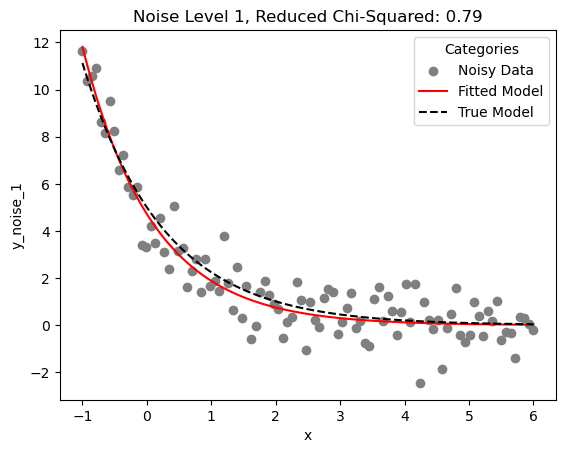

In [4]:
plt.scatter(df['x'], df['y_noise_1'], color='grey', label='Noisy Data')
plt.ylabel('x')
plt.xlabel('y_noise_1')
plt.title('Noise_1')
plt.legend(title="Categories", loc="upper right")

def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1, 1]
popt, pcov = curve_fit(model, df['x'], df['y_noise_1'], p0=p0)
A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = df['y_noise_1'] - model(df['x'], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(df['x']) - len(popt)
chi2_reduced = chi2 / dof

x_sorted = np.sort(df['x'])

plt.plot(x_sorted, model(x_sorted, A_fit, k_fit), color ='red', label='Fitted Model')
plt.plot(x_sorted, model(x_sorted, 5, 0.8), color='black', linestyle='--', label='True Model')

plt.xlabel('x')
plt.ylabel('y_noise_1')
plt.title(f"Noise Level 1, Reduced Chi-Squared: {chi2_reduced:.2f}")
plt.legend(title="Categories", loc="upper right")
plt.show()

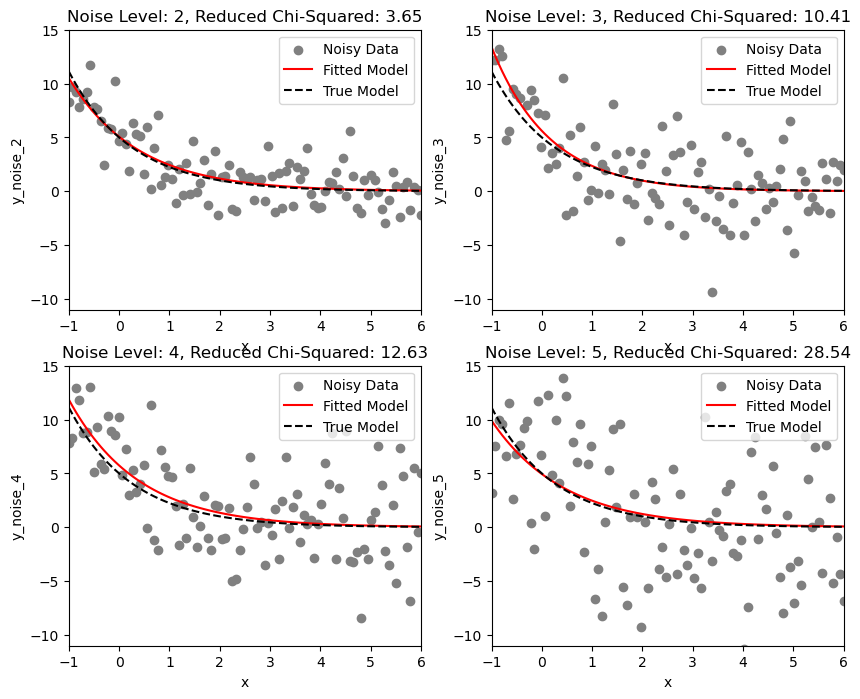

In [ ]:
def fit_model(x, y):
    p0 = [1, 1]
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return A_fit, k_fit, chi2_reduced

fig, axes = plt.subplots(2, 2, figsize=(10,8))
noise_columns = ['y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']
x_sort = np.sort(df['x'])

for i, (ax, col) in enumerate(zip(axes.flatten(), noise_columns)):
    noise_level = i + 2
    A_fit, k_fit, chi2_reduced = fit_model(df['x'], df[col])
    
    ax.scatter(df['x'], df[col], color='gray', label='Noisy Data')
    ax.plot(x_sorted, model(x_sorted, A_fit, k_fit), color='red', label='Fitted Model')
    ax.plot(x_sorted, model(x_sorted, 5, 0.8), color='black', linestyle='--', label='True Model')
    
    ax.set_title(f"Noise Level: {noise_level}, Reduced Chi-Squared: {chi2_reduced:.2f}")
    ax.set_xlabel('x')
    ax.set_ylabel(col)
    ax.legend(loc='upper right')
    ax.set_xlim(df['x'].min(), df['x'].max())
    ax.set_ylim(-11, 15)

In [27]:
# The black line seems to be remaining in place while red red lines move a little, randomly above or below
# The chi squared value meanwhile is steadily increasing as the noise does 

results = []
for i in range(1,6):
    col = f"y_noise_{i}"
    A_fit, k_fit, chi2_reduced = fit_model(df['x'], df[col])
    results.append({
        "Noise level": i,
        "A fit": A_fit,
        "k fit": k_fit,
        "Reduced chi-squared": chi2_reduced
    })
new_df = pd.DataFrame(results)
print(new_df.shape)
display(new_df)
new_df.to_csv("noisy_parameters.csv")

(5, 4)


,Noise level,A fit,k fit,Reduced chi-squared
0,1,4.714814,0.918308,0.790673
1,2,5.063889,0.730396,3.649382
2,3,5.609396,0.870372,10.410207
3,4,5.738727,0.725965,12.626832
4,5,4.943458,0.695012,28.538124


<!-- 4) The black line seems to stay in place, and the red line is moving, but there doesn't seem to be a pattern. Meanwhile, the chi squared value is increasing throughout.-->